DSC 210 -- Exam 1 Takehome -- Spring 2026

Name: Jacob Bauer

# Question One

The files `patient_demographics.csv`, `patient_sleep.csv`, and `patient_lifestyle.csv` contain data on sleep health and lifestyle factors of individuals. They record demographic details, occupation, sleep duration, sleep quality, stress levels, BMI categories, blood pressure, heart rate, physical activity, and the presence of sleep disorders. Use these files to answer the following questions. **(30 points total)**

1. Is there a relationship between quality of sleep and amount of sleep for these individuals? Create a data visualization and compute relevant summary statistics to help answer this question.

        Person ID  Sleep Duration  Quality of Sleep
count   91.000000       91.000000         91.000000
mean   111.472527        7.394505          7.824176
std     49.569332        0.277434          0.436995
min      8.000000        7.100000          7.000000
25%     90.500000        7.200000          8.000000
50%    120.000000        7.200000          8.000000
75%    144.500000        7.700000          8.000000
max    219.000000        8.000000          9.000000


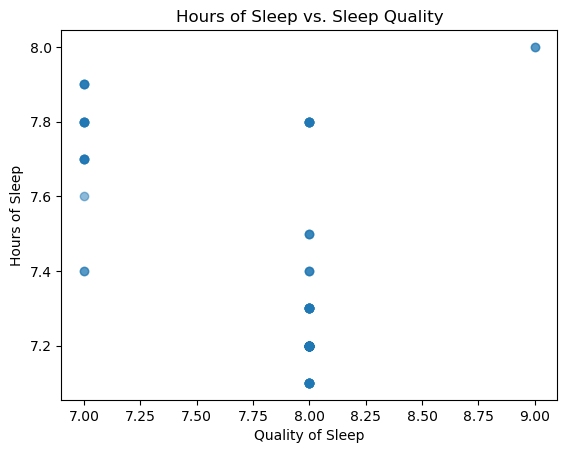

array([[ 1.        , -0.45713092],
       [-0.45713092,  1.        ]])

In [15]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns 
import numpy as np

demographics_df = pd.read_csv("patient_demographics.csv")
lifestyle_df = pd.read_csv("patient_lifestyle.csv")
sleep_df = pd.read_csv("patient_sleep.csv")
subgroup_df = pd.read_csv("patient_subgroup.csv")

print(sleep_df.describe())
plt.scatter(sleep_df["Quality of Sleep"], sleep_df["Sleep Duration"], alpha = 0.5)
plt.xlabel("Quality of Sleep")
plt.ylabel("Hours of Sleep")
plt.title("Hours of Sleep vs. Sleep Quality")
plt.show()
np.corrcoef(sleep_df["Sleep Duration"], sleep_df["Quality of Sleep"])

# When looking at the scatter plot and the correlation coef, we can see that there is a slight negative relationship in hours slept vs quality of sleep.
# This means that people reported having better sleep while sleeping less hours.

2. Is there a difference between average amount of sleep between different BMI categories? Create a data visualization to answer this question. What issues does this visualization show? (You do not need to fix/clean the dataset to address the issues, just identify them.)

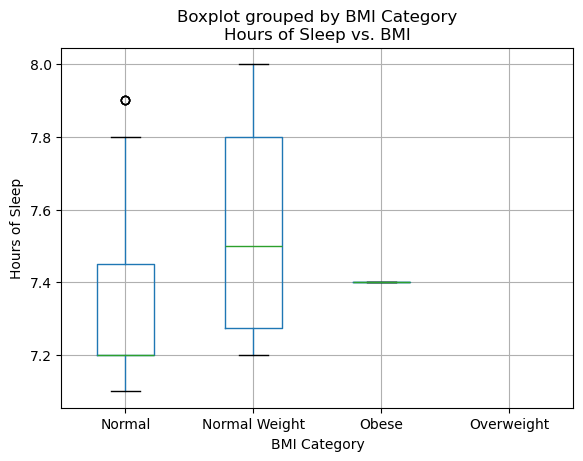

Person ID                    0
Sleep Duration             269
Quality of Sleep           269
Sleep Disorder             351
Physical Activity Level      3
Stress Level                 3
BMI Category                 3
Blood Pressure               3
Heart Rate                   3
Daily Steps                  3
dtype: int64
Length of dataframe: 360


In [23]:
sleep_lifestyle_df = pd.merge(sleep_df, lifestyle_df, how = "outer")
sleep_lifestyle_df.head()

sleep_lifestyle_df.boxplot(column = "Sleep Duration", by = "BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Hours of Sleep")
plt.title("Hours of Sleep vs. BMI")
plt.show()

# The issues I see in the data visualization are that there is a normal category and a normal weight category. Even though they mean
# the same thing they are split into two different categories, causing the true mean for this category to not be represented accuratley.
# Another issue is that when joining the data frames together, there is a lot of missing data. Most of the ID numbers do not match up 
# between the data sets, causing a large portion of observations to not be plotted. 

missing_data = sleep_lifestyle_df.isna()
missing_data_count = missing_data.sum()
print(missing_data_count)
print(f"Length of dataframe: {len(sleep_lifestyle_df)}")

# When looking at the missing data, we can see that there are 269 total observations missing in the sleep duration category, making 
# it very difficult to accuratly plot the data.
# There is not much of a relationship to be seen between the BMI Categories and Hours of Sleep.

3. Use a generative AI program (like ChatGPT) to test the research question "Is there a difference between average amount of sleep between different BMI categories?" based on the patient data. Report the prompt you used, the resulting code produced, and the resulting answer (with p-value) in context of the question.

In [31]:
sleep_lifestyle_df.head()
import scipy.stats as stats

sleep_lifestyle_clean = sleep_lifestyle_df.dropna(subset=["Sleep Duration", "BMI Category"])

# Group sleep duration by BMI category
groups = [group["Sleep Duration"].values
          for name, group in sleep_lifestyle_clean.groupby("BMI Category")]

# Perform one-way ANOVA
f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_stat)
print("p-value:", p_value)

# Prompt: Use a generative AI program (like ChatGPT) to test the research question "Is there a difference between average amount of 
# sleep between different BMI categories?" based on the patient data. Report the prompt you used, the resulting code produced, 
# and the resulting answer (with p-value) in context of the question. let me give you the actual names of the columns in the joint 
# data set: Person ID Sleep Duration Quality of Sleep Sleep Disorder Physical Activity Level Stress Level BMI Category Blood Pressure 
# Heart Rate Daily Steps
# Based on the reported p-value we can see that there is not a statistical difference between Hours of sleep and BMI Category,
# where alpha > 0.05. 

F-statistic: 2.8875917798096737
p-value: 0.061192905142608764


4. Suppose a forgetful data scientist created the file labeled `patient_subgroup.csv`, using the three patient `.csv` files described above, but cannot remember how they did so. There code has been lost!  Recreate this dataframe using joins and filters.

In [47]:
merge_sleep_lifestyle = pd.merge(sleep_df, lifestyle_df, "inner")
merge_all_df = pd.merge(merge_sleep_lifestyle, demographics_df, "inner")
print(f"Length of dataframe: {len(merge_all_df)}")
#print(merge_all_df.head())
#print(subgroup_df.head())


new_subgroup_df = merge_all_df[(merge_all_df["Sleep Disorder"] == "Insomnia") | (merge_all_df["Sleep Disorder"] == "Sleep Apnea")]
print(f"Length of new_subgroup_df: {len(new_subgroup_df)}")
new_subgroup_df.head(7)

Length of dataframe: 88
Length of new_subgroup_df: 7


,Person ID,Sleep Duration,Quality of Sleep,Sleep Disorder,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Gender,Age,Occupation
26,94,7.4,7,Sleep Apnea,60,5,Obese,135/88,84,3300,Male,35.0,Lawyer
27,95,7.2,8,Insomnia,60,4,Normal,115/75,68,7000,Female,36.0,Accountant
32,105,7.2,8,Sleep Apnea,60,4,Normal,115/75,68,7000,Female,36.0,Teacher
68,145,7.1,8,Sleep Apnea,60,5,Normal,130/85,68,8000,Male,38.0,Lawyer
69,146,7.4,7,Sleep Apnea,60,5,Obese,135/88,84,3300,Female,38.0,Lawyer
70,147,7.2,8,Insomnia,60,5,Normal,130/85,68,8000,Male,39.0,Lawyer
87,203,7.8,8,Insomnia,90,5,Normal,130/85,70,8000,Male,43.0,Engineer


# Question Two

You are given a Python script that loads a dataset of used car sales and performs cleaning, feature engineering, and visualization.
The file `used_cars.csv`  contains the following features:
- `price`: sale price of the car (float)
- `year`: manufacturing year (int)
- `mileage`: miles driven (float)
- `engine_size`: engine size in liters (float)
- `fuel_type`: Petrol, Diesel, Hybrid (string)
- `transmission`: Manual or Automatic (string)
- `owners`: number of previous owners (int)
- `sale_date`: date of sale (string)

This script contains conceptual and data-processing errors. Your task is to:
- Identify at least **five** error/problems/omissions in the code
- For each error/problem:
  - Explain why the error is problematic
  - Suggest a corrected version or improvement (description or pseudocode)

You may add comments directly in the code itself or answer in a text box below the code.

Note: you do not have access to the dataset for this analysis, so the code below does not actually run.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("used_cars.csv")

# Quick inspection
print(df.head())
print(df.describe())

# Remove missing values
df = df[df != np.nan] # This will not remove any missing values from the data set because df does not equal nan is always true.

# df = df.dropna() -> This will drop all na values from the data frame.

# Convert sale_date to datetime
df["sale_date"] = pd.to_datetime(df["sale_date"])

# Create car age feature (assuming current year is 2024)
df["car_age"] = 2024 - df["year"] # Although this will work, it is never a good idea to hard code in a year value to your code, 
# instead, you should make a year variable set to equal the current year, this will easily allow someone to go in and change the year.

# curr_year = 2024
# df["car_age"] = curr_year - df["year"]

# Replace missing mileage with 0
df["mileage"] = df["mileage"].fillna(0) # Filling na with the value 0 can cause issues later in the code. In this case when you are trying
# to make a new column for price per mile, any value that was previously na is now a 0. In this case you should get rid of the 0 values.

# df = df[df["milage"] > 0]

# Remove cars with price equal to 0
df = df[df["price"] > 0]

# Create price per mile feature
df["price_per_mile"] = df["price"] / df["mileage"] # Here you should be careful that there are no cars with a milage of 0

# df = df[df["milage"] > 0]
# df["price_per_mile"] = df["price"] / df["mileage"]

# Correlation matrix
corr = df.corr() # This could raise some issues since the .corr() method only takes numeric values and this data set contains nonnumeric values.
print(corr)

# corr = df.select_dtypes(include="number").corr()
# print(corr)

# Scatter plot: mileage vs price
plt.scatter(df["mileage"], df["price"])
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.title("Price vs Mileage")
plt.show()

# Bar chart: average price by fuel type
avg_price = df.groupby("fuel_type")["price"].mean()
avg_price.plot(kind="bar")
plt.title("Average Price by Fuel Type")
plt.show()